In [440]:
! pip install optuna

In [441]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
import optuna
import numpy as np

In [442]:
df = pd.read_csv('housing.csv')
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [443]:
df.shape

(506, 14)

# Задание 1

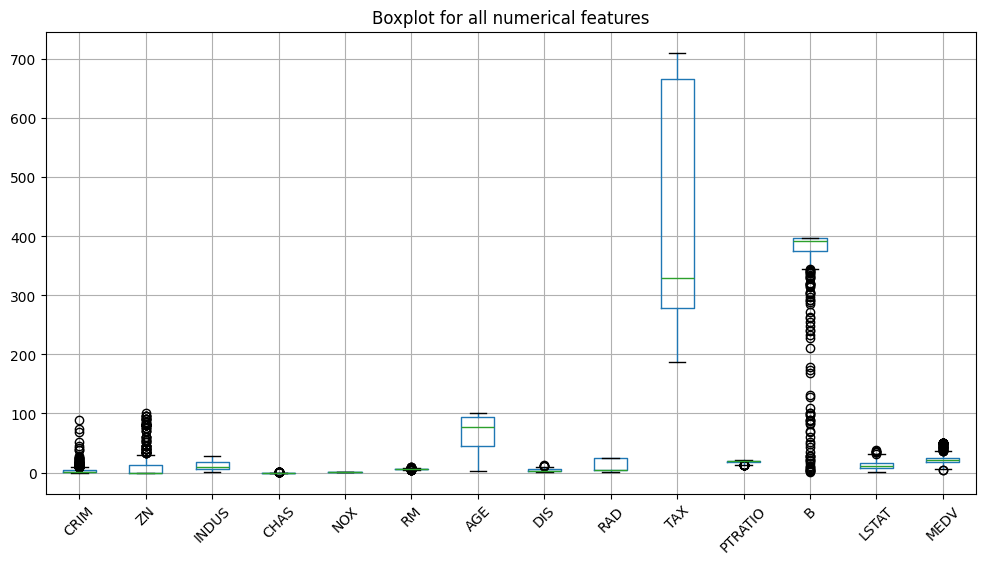

In [444]:
plt.figure(figsize=(12, 6))
df.boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot for all numerical features")
plt.show()

#### Видно, что данные распределены по-разному, так что применим standart scaler для стандартизации

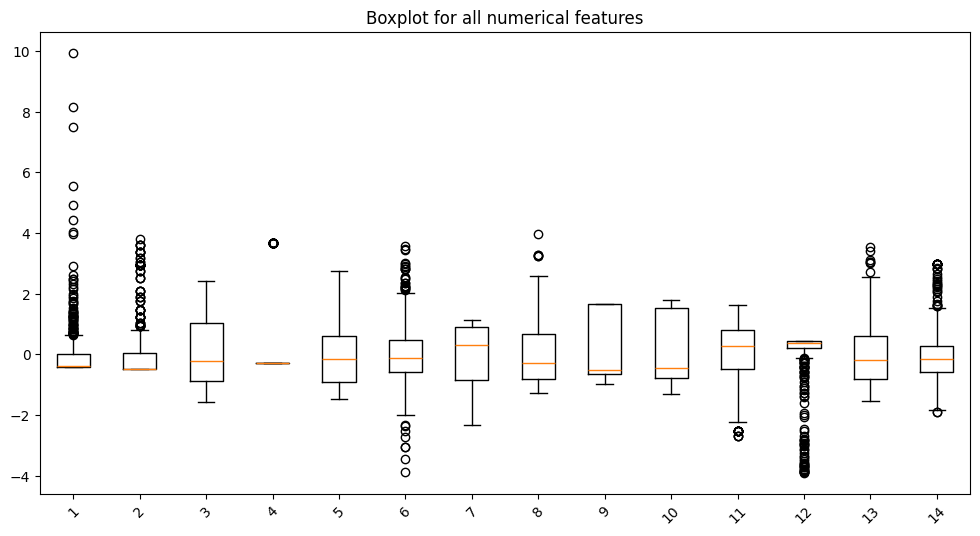

In [445]:
scale = StandardScaler(with_mean=True, with_std=True)
scale.fit(np.array(df))
data_scaled = scale.transform(np.array(df))

plt.figure(figsize=(12, 6))
plt.boxplot(data_scaled)
plt.xticks(rotation=45)
plt.title("Boxplot for all numerical features")
plt.show()

Text(0.5, 1.0, 'Проекция признаков')

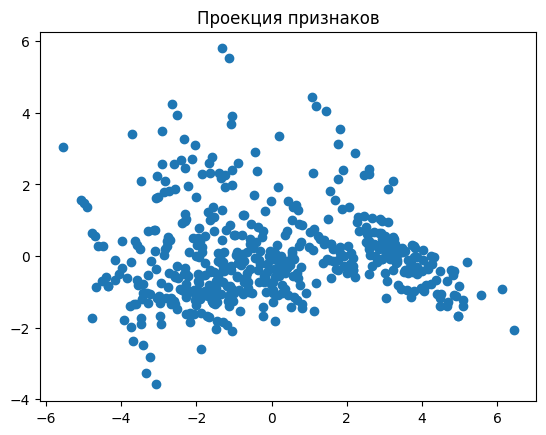

In [446]:
pca = PCA(n_components=0.97)
pca.fit(data_scaled)
K = pca.transform(data_scaled)

plt.scatter(K[:, 0], K[:, 1])
plt.title("Проекция признаков")

#### Число признаков не избыточное, поэтому я не понимаю, зачем лишний раз выбирать признаки. Использую PCA с большой долей для удаления коллинеарных признаков.

# Задание 2

Best slhouette_score:	 0.36055697646224916


Text(0.5, 1.0, 'Кластеры')

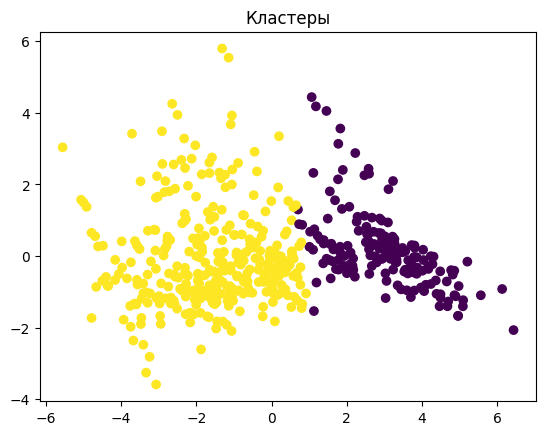

In [447]:
best_n = -1
best_score = -1

for n in range(2, 10):
  cls = KMeans(n_clusters=n, random_state=8)
  cls.fit(K)
  cls_labels = cls.labels_
  score = silhouette_score(K, cls_labels)

  if (score > best_score):
    best_score = score
    best_n = n

# лучший результат
cls = KMeans(n_clusters=best_n, random_state=8)
cls.fit(K)
cls_labels = cls.labels_
score = silhouette_score(K, cls_labels)
print("Best slhouette_score:\t", score)
plt.scatter(K[:, 0], K[:, 1], c=cls_labels)
plt.title("Кластеры")

In [448]:
def objective(trial):
    n_clusters = trial.suggest_int("n_clusters", 2, 20)
    n_init = trial.suggest_int("n_init", 5, 20)
    max_iter = trial.suggest_int("max_iter", 100, 500)
    algorithm = trial.suggest_categorical("algorithm", ["lloyd", "elkan"])

    model = KMeans(
        n_clusters=n_clusters,
        n_init=n_init,
        max_iter=max_iter,
        algorithm=algorithm,
        random_state=8
    )

    model.fit(K)
    labels = model.labels_

    if len(set(labels)) == 1:
        return -1.0

    score = silhouette_score(K, labels)
    return score


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best params:")
print(study.best_params)

print("Best silhouette_score:\t", study.best_value)

[I 2025-12-04 22:46:16,137] A new study created in memory with name: no-name-9dc45cde-d4e7-4fe5-9da0-0eb3d20f6858
[I 2025-12-04 22:46:16,260] Trial 0 finished with value: 0.2818171042724489 and parameters: {'n_clusters': 9, 'n_init': 17, 'max_iter': 364, 'algorithm': 'elkan'}. Best is trial 0 with value: 0.2818171042724489.
[I 2025-12-04 22:46:16,459] Trial 1 finished with value: 0.25565911673084346 and parameters: {'n_clusters': 19, 'n_init': 17, 'max_iter': 432, 'algorithm': 'elkan'}. Best is trial 0 with value: 0.2818171042724489.
[I 2025-12-04 22:46:16,539] Trial 2 finished with value: 0.28806118000214087 and parameters: {'n_clusters': 6, 'n_init': 17, 'max_iter': 235, 'algorithm': 'lloyd'}. Best is trial 2 with value: 0.28806118000214087.
[I 2025-12-04 22:46:16,594] Trial 3 finished with value: 0.2544845345102986 and parameters: {'n_clusters': 3, 'n_init': 7, 'max_iter': 192, 'algorithm': 'elkan'}. Best is trial 2 with value: 0.28806118000214087.
[I 2025-12-04 22:46:16,660] Trial 

Best params:
{'n_clusters': 2, 'n_init': 20, 'max_iter': 404, 'algorithm': 'lloyd'}
Best silhouette_score:	 0.36055697646224916


#### Optuna ничего не улучшила, результат буквально такой же

# Задание 3

In [449]:
Xtrain, Xtest = train_test_split(df, test_size=0.3, random_state=8)

scaler = StandardScaler()
scaler.fit(Xtrain)

Xtrain_scaled = scaler.transform(Xtrain)
Xtest_scaled = scaler.transform(Xtest)

pca = PCA(n_components=0.97)
Xtrain_pca = pca.fit_transform(Xtrain_scaled)
Xtest_pca = pca.transform(Xtest_scaled)

In [450]:
model = KMeans(n_clusters=2, random_state=8)
model.fit(Xtrain_pca)

ytrain = model.labels_

In [451]:
# clf = SVC(kernel='poly', degree=4, coef0=1, C=2) # если степень меньше 4х, то больше несовпадений с KMeans (2)
# clf.fit(Xtrain_pca, ytrain)
# clf_labels = clf.predict(Xtest_pca)

In [452]:
X, y = Xtrain_pca, ytrain

def objective(trial):
    kernel = trial.suggest_categorical("kernel", ["poly", "linear"])
    degree = trial.suggest_int("degree", 4, 6) # если степень меньше 4х, то больше несовпадений с KMeans (2)
    C = trial.suggest_float("C", 0.1, 10.0, log=True)
    gamma = trial.suggest_float("gamma", 0.01, 1.0, log=True)
    coef0 = trial.suggest_float("coef0", 0.0, 5.0)
    shrinking = trial.suggest_categorical("shrinking", [True, False])
    tol = trial.suggest_float("tol", 1e-5, 1e-2, log=True)
    class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])

    clf = SVC(
        kernel=kernel,
        degree=degree,
        C=C,
        gamma=gamma,
        coef0=coef0,
        shrinking=shrinking,
        tol=tol,
        class_weight=class_weight,
    )

    score = cross_val_score(clf, X, y, cv=StratifiedKFold(n_splits=5), scoring='accuracy')
    return score.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Лучшие параметры:", study.best_params)
print("Лучший результат:", study.best_value)


[I 2025-12-04 22:46:20,525] A new study created in memory with name: no-name-b1b5db2b-fb9a-4b4e-95ff-897bb4861d80
[I 2025-12-04 22:46:20,561] Trial 0 finished with value: 0.9774245472837023 and parameters: {'kernel': 'linear', 'degree': 4, 'C': 1.0988409718187322, 'gamma': 0.01064144799935796, 'coef0': 4.83441105700193, 'shrinking': False, 'tol': 0.0056554206147478156, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9774245472837023.
[I 2025-12-04 22:46:20,590] Trial 1 finished with value: 0.9802414486921529 and parameters: {'kernel': 'poly', 'degree': 5, 'C': 1.495854944207035, 'gamma': 0.018645153155718453, 'coef0': 4.803565182397243, 'shrinking': False, 'tol': 0.0022956816874203146, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.9802414486921529.
[I 2025-12-04 22:46:20,616] Trial 2 finished with value: 0.9830583501006036 and parameters: {'kernel': 'poly', 'degree': 4, 'C': 0.1796252752910227, 'gamma': 0.13240860492875495, 'coef0': 3.9384210402916016, 'shrinkin

Лучшие параметры: {'kernel': 'linear', 'degree': 4, 'C': 4.3186486210649635, 'gamma': 0.01941521753768017, 'coef0': 0.7911105633558966, 'shrinking': False, 'tol': 0.002636633346131631, 'class_weight': 'balanced'}
Лучший результат: 0.9943661971830986


In [453]:
clf = SVC(**study.best_params)
clf.fit(Xtrain_pca, ytrain)
clf_labels = clf.predict(Xtest_pca)

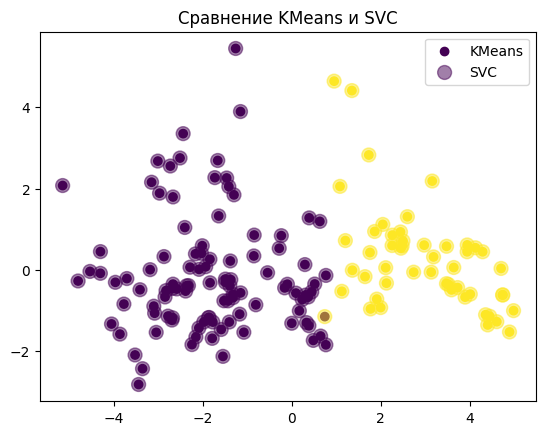

In [454]:
Xtest_pca_2d = Xtest_pca[:, :2]

plt.scatter(Xtest_pca_2d[:, 0], Xtest_pca_2d[:, 1], c=model.predict(Xtest_pca), label='KMeans')
plt.scatter(Xtest_pca_2d[:, 0], Xtest_pca_2d[:, 1], c=clf_labels, alpha=0.5, s=100, label='SVC')
plt.title("Сравнение KMeans и SVC")
plt.legend()

#### Хороший результат, мало несовпадений

# Задание 4

In [455]:
data_scaled_full = scale.transform(df)
data_pca_full = pca.transform(data_scaled_full)
model_labels_full = model.predict(data_pca_full)

df["class"] = model_labels_full

r = np.random.RandomState(8)
n = 100
cv_values = np.linspace(0.0, 10.0, 20)

accuracy_list = []
saved_data = None
saved_labels = None
saved_predictions = None
res_cv = 0

for cv in cv_values:
    data_add = []
    cls_add_labels = []

    for i in np.unique(model_labels_full):
        cluster_data = df[df['class'] == i].iloc[:, :-1].values
        mu = cluster_data.mean(axis=0)
        sigma = cluster_data.std(axis=0, ddof=1)
        sigma_noise = sigma * cv

        add = r.normal(loc=mu, scale=sigma_noise, size=(n, cluster_data.shape[1]))
        data_add.append(add)
        cls_add_labels.extend([i] * n)

    data_add = np.vstack(data_add)
    cls_add_labels = np.array(cls_add_labels)

    data_add_scaled = scale.transform(data_add)
    data_add_pca = pca.transform(data_add_scaled)

    clf_add_labels = clf.predict(data_add_pca)

    acc = accuracy_score(cls_add_labels, clf_add_labels)
    accuracy_list.append(acc)

    print(f"CV={cv:.2f}, Accuracy={acc:.4f}")

    if acc <= 0.7 and saved_data is None:
        res_cv = cv
        saved_data = data_add_pca
        saved_labels = cls_add_labels
        saved_predictions = clf_add_labels
        print(f"Точность SVM упала до {acc:.4f} при CV ≈ {cv:.2f}")

CV=0.00, Accuracy=1.0000
CV=0.53, Accuracy=1.0000
CV=1.05, Accuracy=0.9950
CV=1.58, Accuracy=0.9700
CV=2.11, Accuracy=0.9350
CV=2.63, Accuracy=0.9250
CV=3.16, Accuracy=0.8300
CV=3.68, Accuracy=0.8100
CV=4.21, Accuracy=0.8050
CV=4.74, Accuracy=0.6500
Точность SVM упала до 0.6500 при CV ≈ 4.74
CV=5.26, Accuracy=0.7350
CV=5.79, Accuracy=0.6800
CV=6.32, Accuracy=0.6800
CV=6.84, Accuracy=0.6950
CV=7.37, Accuracy=0.6750
CV=7.89, Accuracy=0.6500
CV=8.42, Accuracy=0.5900
CV=8.95, Accuracy=0.6650
CV=9.47, Accuracy=0.6500
CV=10.00, Accuracy=0.6200


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


# Задание 5


Финальная проверка - Accuracy=0.6500


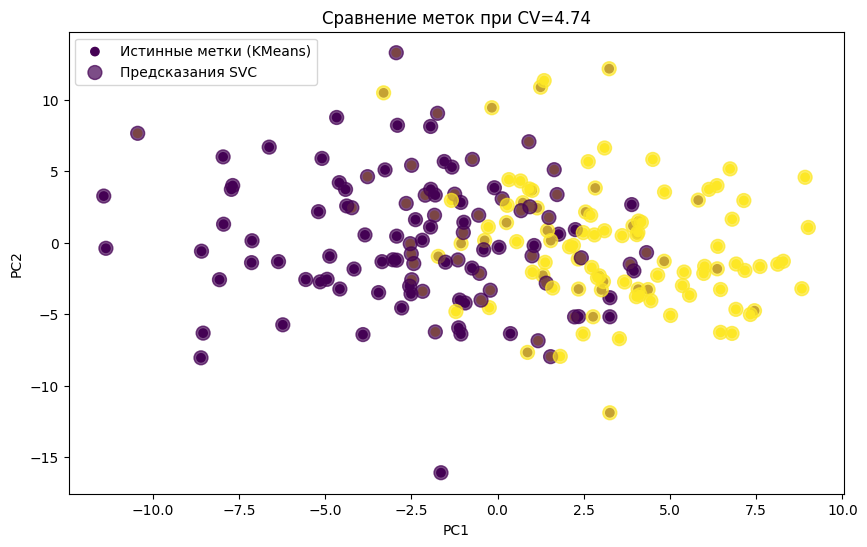

In [456]:
acc = accuracy_score(saved_labels, saved_predictions)
print(f"\nФинальная проверка - Accuracy={acc:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(saved_data[:, 0], saved_data[:, 1], c=saved_labels, label='Истинные метки (KMeans)')
plt.scatter(saved_data[:, 0], saved_data[:, 1], c=saved_predictions, alpha=0.7, s=100, label='Предсказания SVC')
plt.title(f'Сравнение меток при CV={res_cv:.2f}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()